In [1]:
from domino.data.data import *
from scipy import stats
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
import matplotlib.pyplot as plt
from domino.utils.tools import seq_from_df
import pandas as pd
import seaborn as sns
import os

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'
import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

In [2]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

DNA_context_bin_width=16
DNA_context_length = 200*DNA_context_bin_width


TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

def add_residual_column(df):
    df['residual'] = df['demeaned_ins_score_1'] - df['pred']
    df['abs_residual'] = (df['demeaned_ins_score_1'] - df['pred']).abs()
    
for df in [TRAIN_df, VAL_df, TEST_df]:
    df = add_residual_column(df)
    
genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

print(os.listdir(model_dir + '/checkpoint')[0])

model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
data = fanc.load(f'{data_dir}/mcools/new_nc14_embryo_merged_all_{num_merged}.mcool@{resolution}')

epoch=9-step=83001.ckpt


/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


fc dim 206
extra dim 6


## Motifs discovered by TFModisco

In [3]:
import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import h5py

TFMODISCO_WINDOW=600

out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff/'
modisco_results = h5py.File(f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")

# ADAPTED FROM https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179
trim_threshold = 0.3
pattern_cwms = {}
names = ['pos_patterns', 'neg_patterns'] 
for name in names:
    metacluster = modisco_results[name]
    key = lambda x: int(x[0].split("_")[-1])
    for pattern_name, pattern in sorted(metacluster.items(), key=key):
        tag = '{}.{}'.format(name, pattern_name)
        num_seqlets = pattern['seqlets']['n_seqlets'][:][0]
       
        cwm_fwd = np.array(pattern['contrib_scores'][:])
        cwm_rev = cwm_fwd[::-1, ::-1] # reverse complement
        
        # base pair contribution score is sum of attribution across position
        score_fwd = np.sum(np.abs(cwm_fwd), axis=1) 
        score_rev = np.sum(np.abs(cwm_rev), axis=1)
        
        # cut off anything less than 30% of max score
        trim_thresh_fwd = np.max(score_fwd) * trim_threshold 
        trim_thresh_rev = np.max(score_rev) * trim_threshold
        
        pass_inds_fwd = np.where(score_fwd >= trim_thresh_fwd)[0]
        pass_inds_rev = np.where(score_rev >= trim_thresh_rev)[0]
    
        # include flanking 4 bases left and right
        start_fwd, end_fwd = max(np.min(pass_inds_fwd) - 4, 0), min(np.max(pass_inds_fwd) + 4 + 1, len(score_fwd) + 1)
        start_rev, end_rev = max(np.min(pass_inds_rev) - 4, 0), min(np.max(pass_inds_rev) + 4 + 1, len(score_rev) + 1)
        
        trimmed_cwm_fwd = cwm_fwd[start_fwd:end_fwd]
        trimmed_cwm_rev = cwm_rev[start_rev:end_rev]
        
        pattern_cwms[tag] = {'fwd': trimmed_cwm_fwd, 'rev': trimmed_cwm_rev, 'num_seqlets': num_seqlets}

modisco_results.close()

In [4]:
def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets and q_val:
        ax.set_title(f"{pattern_name}, {num_seqlets}, {q_val}")

In [5]:
avg_attrs = []
for name, cwm in pattern_cwms.items():
    assert(round(cwm['fwd'].mean(), 5) == round(cwm['rev'].mean(), 5))
    avg_attrs.append(cwm['fwd'].sum()/cwm['fwd'].shape[0])

average_attr_df = pd.DataFrame({'name': pattern_cwms.keys(), 'avg_attr': avg_attrs})
pattern_df = average_attr_df.sort_values('avg_attr')
pattern_attr = pattern_df.avg_attr
pattern_attr.index = pattern_df.name


In [6]:
from modiscolite.report import generate_tomtom_dataframe
import h5py

In [7]:
out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff'
modisco_h5py = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
output_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/tmp'
meme_motif_db = f"/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/JASPAR2024_CORE_insects_non-redundant_pfms_meme.txt"
is_writing_tomtom_matrix = False 
pattern_groups = ['pos_patterns', 'neg_patterns']
top_n_matches=3
tomtom_exec = "tomtom"
trim_threshold=0.3
trim_min_length=3

In [8]:
results = {'pattern': [], 'num_seqlets': [], 'modisco_cwm_fwd': [], 'modisco_cwm_rev': []}
img_path_suffix = f'/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff'
with h5py.File(modisco_h5py, 'r') as modisco_results:
    for name in pattern_groups:
        if name not in modisco_results.keys():
            continue

        metacluster = modisco_results[name]
        key = lambda x: int(x[0].split("_")[-1])
        for pattern_name, pattern in sorted(metacluster.items(), key=key):
            num_seqlets = pattern['seqlets']['n_seqlets'][:][0]
            pattern_tag = f'{name}.{pattern_name}'

            results['pattern'].append(pattern_tag)
            results['num_seqlets'].append(num_seqlets)
            results['modisco_cwm_fwd'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.fwd.png'))
            results['modisco_cwm_rev'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.rev.png'))

patterns_df = pd.DataFrame(results)
tomtom_df = generate_tomtom_dataframe(modisco_h5py, output_dir, meme_motif_db, is_writing_tomtom_matrix, pattern_groups)
patterns_df = pd.concat([patterns_df, tomtom_df], axis=1)

final_patterns_df = patterns_df[['pattern', 'num_seqlets', 'match0', 'qval0',	'match1',	'qval1', 'match2',	'qval2']]

avg_attrs = []
for name, cwm in pattern_cwms.items():
    assert(round(cwm['fwd'].mean(), 5) == round(cwm['rev'].mean(), 5))
    avg_attrs.append(cwm['fwd'].sum()/cwm['fwd'].shape[0])

final_patterns_df['avg_attr'] = avg_attrs
final_patterns_df = final_patterns_df.sort_values('avg_attr').reset_index(drop=True)

/tmp/ipykernel_3618854/956793213.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_patterns_df['avg_attr'] = avg_attrs


In [9]:
import sys
sys.path.append('../../../python_modules/')
from load_modisco import *
def get_pattern_matrices(out_folder, TFMODISCO_WINDOW, num_flanking_bases):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases)
    return pattern_cwms, pattern_pwms

In [10]:
_, pattern_pwms = get_pattern_matrices(out_folder, 600, num_flanking_bases=4)
def compute_total_info_content(pattern):
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic_track = compute_per_position_ic(pattern_pwms[pattern]['fwd'], background, 0.001)
    # plt.plot(ic_track)
    # plt.title(npatterns2targets[pattern][0])
    # plt.ylabel('Information Content (Bits)')
    # plt.xlabel('Position')
    return ic_track.sum()

def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} {num_seqlets} {"{:.3e}".format(qval)}')

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

def trim_cwm(cwm, trim_threshold=0.3):
    # get abs score of each base pair (so this will be of length 30)
    score = np.sum(np.abs(cwm), axis=1) 
    # cut off anything less than 30% of max score
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]
    # include flanking 4 bases left and right
    start, end = max(np.min(pass_inds) - 4, 0), min(np.max(pass_inds) + 4 + 1, len(score) + 1)
    trimmed_cwm = cwm[start:end]
    
    return trimmed_cwm

In [13]:
final_patterns_df['total_ic'] = [compute_total_info_content(p) for p in final_patterns_df.pattern]

In [14]:
from tangermeme.io import read_meme
import logomaker
import json

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig2_motif_discovery/all_nc14_pattern_to_target_dict.json', 'r') as f:
    npatterns2targets = json.load(f)
    
MIN_NUM_SEQLETS = 85
MIN_IC = 7

final_patterns_df_filtered = final_patterns_df.query('num_seqlets > @MIN_NUM_SEQLETS and pattern.str.contains("neg") and total_ic > @MIN_IC')
final_patterns_df_filtered = final_patterns_df_filtered.reset_index(drop=True)
final_patterns_df_filtered['target'] = [npatterns2targets[p][0] for p in final_patterns_df_filtered.pattern]
final_patterns_df_filtered['reference'] = [npatterns2targets[p][1] for p in final_patterns_df_filtered.pattern]


In [15]:
import json
from tangermeme.io import read_meme
import logomaker

motifs = read_meme(meme_motif_db)

jaspar2pwm = dict()
for key, pwm in motifs.items():
    motif_code, motif_name = key.split(' ')
    jaspar2pwm[motif_code] = {
        'pwm': pwm.numpy(),
        'name': motif_name
    }

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig2_motif_discovery//external_ppms.json', 'r') as f:
    target2extppms = json.load(f)
    


In [16]:
%matplotlib inline
fig, axes = plt.subplots(len(final_patterns_df_filtered) + 1, 7, figsize=(50, len(final_patterns_df_filtered)*2))
for i, row in final_patterns_df_filtered.iterrows():
    i = i+1
    name = row['pattern']
    target = row['target']
    num_seqlets = row['num_seqlets']
    q_val = row['qval0']
    match = row['match0']
    cwm = pattern_cwms[name]
    trimmed_cwm_fwd = cwm['fwd'] * -1
    ref = row['reference']
    
    if target in ['Motif-8', 'M1BP', 'M1BP-alt', 'Motif-7', 'Pita' ,'Pita-long', 'Motif-6', 'Mulberry', 'Su(Hw)', 'AAG3']: 
        trimmed_cwm_fwd = cwm['rev'] * -1
    
    if ref == "JASPAR" or target == 'Motif-8':
        if target == "Motif-8": 
            match = "MA2299.1"
        pwm = make_logo(jaspar2pwm[match]['pwm'].T)
    elif target in target2extppms:
        pwm = make_logo(trim_cwm(np.array(target2extppms[target]).T))
        
    name = target
    max_val = np.max(final_patterns_df_filtered.avg_attr)
    min_val = np.min(final_patterns_df_filtered.avg_attr)
    avg_attr = row['avg_attr']
    
    plot_weights(trimmed_cwm_fwd, axes[i][1])

    axes[i][3].imshow([[avg_attr]], cmap='Reds_r', vmin = min_val, vmax = max_val, aspect='equal')  # 1x1 square

    for j in [0,2,4,6]:
        axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[i][0].text(0, 0, i, ha='center', va='center', fontsize=50)
    axes[i][2].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
    axes[i][4].text(0, 0, name, ha='center', va='center', fontsize=50)
    
    if ref == 'N/A':
        axes[i][6].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    else:
        axes[i][6].text(0, 0, ref, ha='center', va='center', fontsize=50)
        plot_weights(pwm, axes[i][5])
    
    
    j_vals = [0, 2, 3, 4, 6]
    if ref == 'N/A': j_vals.append(5)
    for j in j_vals:
        axes[i][j].set_xticks([])
        axes[i][j].set_yticks([])
        for spine in axes[i][j].spines.values():
            spine.set_visible(False)
        if j != 3:
            axes[i][j].set_xlim(-0.5, 0.5)
            axes[i][j].set_ylim(-0.5, 0.5)

headers = ['#', 'CWM', 'Count', 'Attribution', 'Motif', 'PWM', 'Source']
for j, header in enumerate(headers):
    axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
    axes[0][j].set_xticks([])
    axes[0][j].set_yticks([])
    for spine in axes[0][j].spines.values():
        spine.set_visible(False)

plt.tight_layout()
# plt.savefig("plots/cwms.pdf", format="pdf")
plt.show()

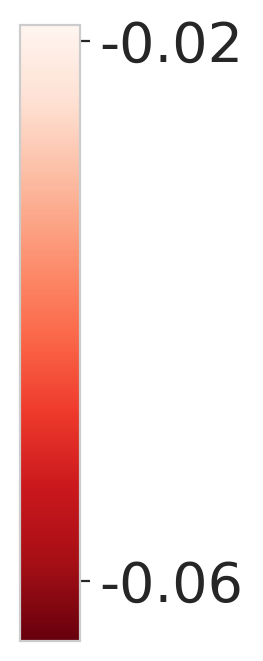

In [17]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Define the colormap and normalization
data = final_patterns_df_filtered.avg_attr.values
vmin, vmax = data.min(), data.max()

p5 = np.percentile(data, 5)
p95 = np.percentile(data, 95)
vmin = np.min(data)
vmax = np.max(data)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='Reds_r', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(1, 4))
fig.subplots_adjust(left=0.5, right=0.8)
cbar = fig.colorbar(sm, cax=ax, ticks=[p5, p95])
cbar.ax.set_yticklabels([f"{p5:.2f}", f"{p95:.2f}"], fontsize=20)
plt.savefig("plots/colorbar.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

In [18]:
# final_patterns_df_filtered[['pattern', 'target']].to_csv('../fig6_synergy/nc14_motifs_for_synergy.csv', index=False)

In [19]:
from tangermeme.io import read_meme
import logomaker
import json

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig2_motif_discovery/all_nc14_pattern_to_target_dict.json', 'r') as f:
    ppatterns2targets = json.load(f)
    
MIN_NUM_SEQLETS = 100
MIN_ATTR = 0.02


final_pos_patterns_df = final_patterns_df.query('num_seqlets > @MIN_NUM_SEQLETS and avg_attr > @MIN_ATTR and pattern.str.contains("pos")')
final_pos_patterns_df['target'] = [ppatterns2targets[p][0] for p in final_pos_patterns_df.pattern]
final_pos_patterns_df['reference'] = [ppatterns2targets[p][1] for p in final_pos_patterns_df.pattern]
final_pos_patterns_df = final_pos_patterns_df.sort_values('avg_attr', ascending=False).reset_index(drop=True)



/tmp/ipykernel_3618854/4014150712.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_pos_patterns_df['target'] = [ppatterns2targets[p][0] for p in final_pos_patterns_df.pattern]
/tmp/ipykernel_3618854/4014150712.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_pos_patterns_df['reference'] = [ppatterns2targets[p][1] for p in final_pos_patterns_df.pattern]


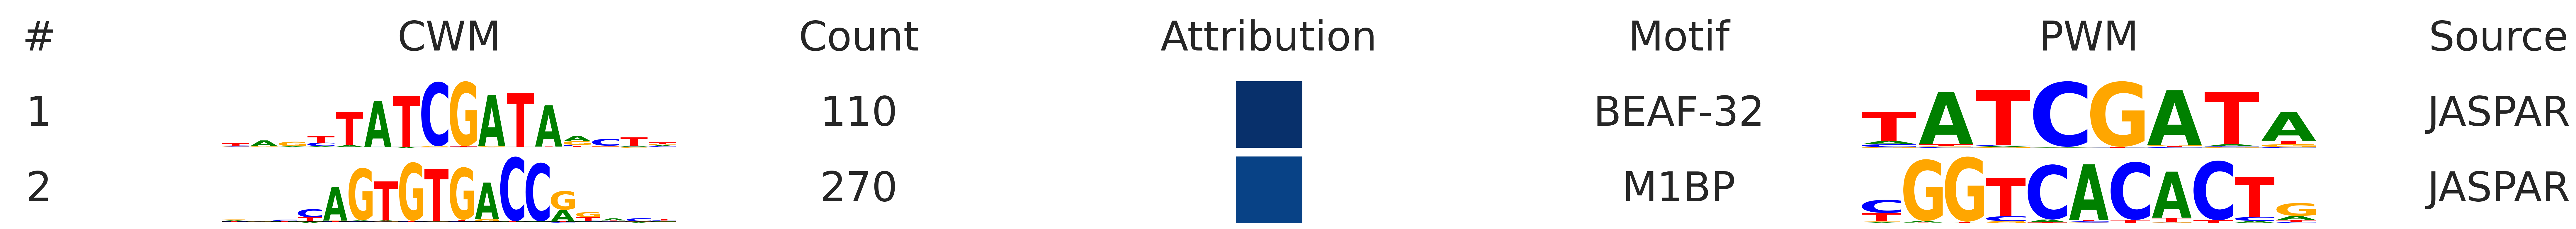

In [20]:
%matplotlib inline
fig, axes = plt.subplots(len(final_pos_patterns_df) + 1, 7, figsize=(50, len(final_pos_patterns_df)*2))
for i, row in final_pos_patterns_df.iterrows():
    i = i+1
    name = row['pattern']
    target = row['target']
    num_seqlets = row['num_seqlets']
    q_val = row['qval0']
    match = row['match0']
    cwm = pattern_cwms[name]
    trimmed_cwm_fwd = cwm['fwd'] 
    ref = row['reference']
    
    if target in ['Zelda1']: 
        trimmed_cwm_fwd = cwm['rev']
    
    if ref == "JASPAR" or target == "CG4854":
        pwm = make_logo(jaspar2pwm[match]['pwm'].T)
    if target in target2extppms:
        pwm = make_logo(trim_cwm(np.array(target2extppms[target]).T))
        
    name = target
    max_val = np.max(final_pos_patterns_df.avg_attr)
    min_val = np.min(final_pos_patterns_df.avg_attr)
    avg_attr = row['avg_attr']
    
    plot_weights(trimmed_cwm_fwd, axes[i][1])

    axes[i][3].imshow([[avg_attr]], cmap='Blues', vmin = 0, vmax = max_val, aspect='equal')  # 1x1 square

    for j in [0,2,4,6]:
        axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[i][0].text(0, 0, i, ha='center', va='center', fontsize=50)
    axes[i][2].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
    axes[i][4].text(0, 0, name, ha='center', va='center', fontsize=50)
    
    if ref == 'N/A':
        axes[i][6].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    else:
        axes[i][6].text(0, 0, ref, ha='center', va='center', fontsize=50)
        plot_weights(pwm, axes[i][5])
    
    
    j_vals = [0, 2, 3, 4, 6]
    if ref == 'N/A': j_vals.append(5)
    for j in j_vals:
        axes[i][j].set_xticks([])
        axes[i][j].set_yticks([])
        for spine in axes[i][j].spines.values():
            spine.set_visible(False)
        if j != 3:
            axes[i][j].set_xlim(-0.5, 0.5)
            axes[i][j].set_ylim(-0.5, 0.5)

headers = ['#', 'CWM', 'Count', 'Attribution', 'Motif', 'PWM', 'Source']
for j, header in enumerate(headers):
    axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
    axes[0][j].set_xticks([])
    axes[0][j].set_yticks([])
    for spine in axes[0][j].spines.values():
        spine.set_visible(False)

plt.tight_layout()
# plt.savefig("plots/positive_cwms.pdf", format="pdf")
plt.show()

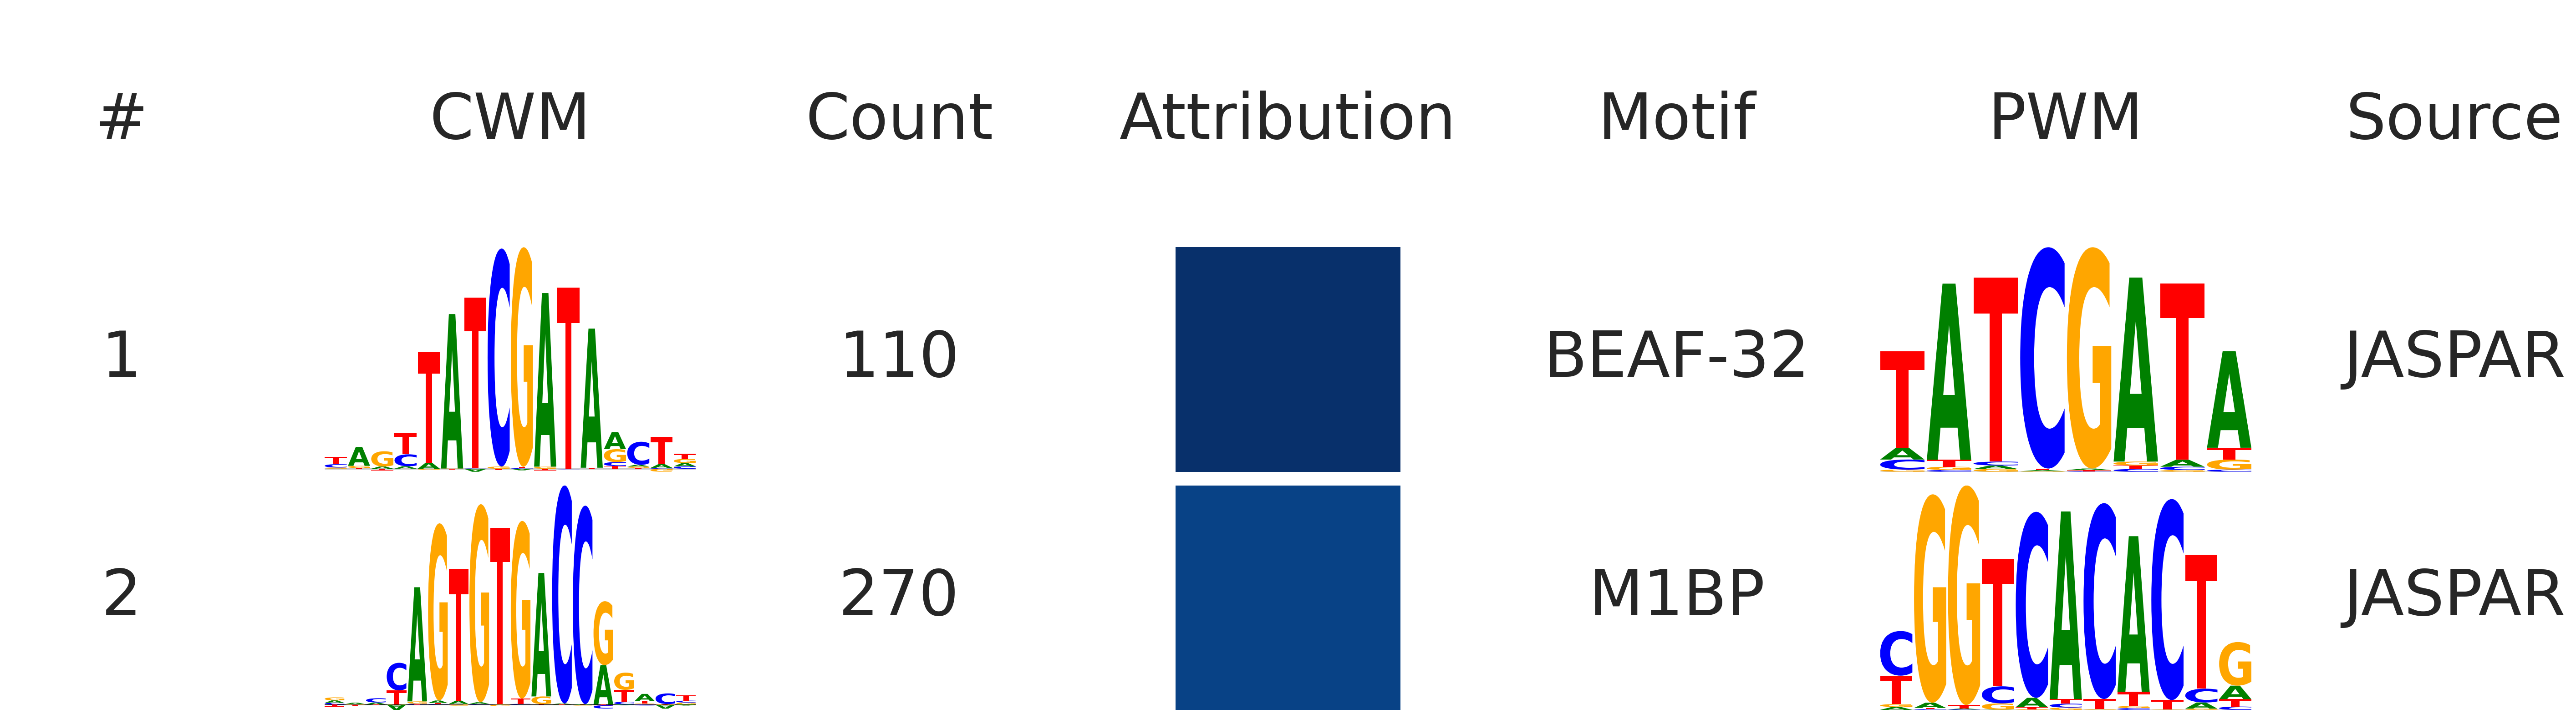

In [21]:
%matplotlib inline
fig, axes = plt.subplots(len(final_pos_patterns_df) + 1, 7, figsize=(30, len(final_pos_patterns_df)*4))
for i, row in final_pos_patterns_df.iterrows():
    i = i+1
    name = row['pattern']
    target = row['target']
    num_seqlets = row['num_seqlets']
    q_val = row['qval0']
    match = row['match0']
    cwm = pattern_cwms[name]
    trimmed_cwm_fwd = cwm['fwd'] 
    ref = row['reference']
    
    if target in ['Zelda1']: 
        trimmed_cwm_fwd = cwm['rev']
    
    if ref == "JASPAR" or target == "CG4854":
        pwm = make_logo(jaspar2pwm[match]['pwm'].T)
    if target in target2extppms:
        pwm = make_logo(trim_cwm(np.array(target2extppms[target]).T))
        
    name = target
    max_val = np.max(final_pos_patterns_df.avg_attr)
    min_val = np.min(final_pos_patterns_df.avg_attr)
    avg_attr = row['avg_attr']
    
    plot_weights(trimmed_cwm_fwd, axes[i][1])

    axes[i][3].imshow([[avg_attr]], cmap='Blues', vmin = 0, vmax = max_val, aspect='equal')  # 1x1 square

    for j in [0,2,4,6]:
        axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[i][0].text(0, 0, i, ha='center', va='center', fontsize=50)
    axes[i][2].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
    axes[i][4].text(0, 0, name, ha='center', va='center', fontsize=50)
    
    if ref == 'N/A':
        axes[i][6].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    else:
        axes[i][6].text(0, 0, ref, ha='center', va='center', fontsize=50)
        plot_weights(pwm, axes[i][5])
    
    
    j_vals = [0, 2, 3, 4, 6]
    if ref == 'N/A': j_vals.append(5)
    for j in j_vals:
        axes[i][j].set_xticks([])
        axes[i][j].set_yticks([])
        for spine in axes[i][j].spines.values():
            spine.set_visible(False)
        if j != 3:
            axes[i][j].set_xlim(-0.5, 0.5)
            axes[i][j].set_ylim(-0.5, 0.5)

headers = ['#', 'CWM', 'Count', 'Attribution', 'Motif', 'PWM', 'Source']
for j, header in enumerate(headers):
    axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
    axes[0][j].set_xticks([])
    axes[0][j].set_yticks([])
    for spine in axes[0][j].spines.values():
        spine.set_visible(False)

plt.tight_layout()
# plt.savefig("plots/positive_cwms.pdf", format="pdf")
plt.show()

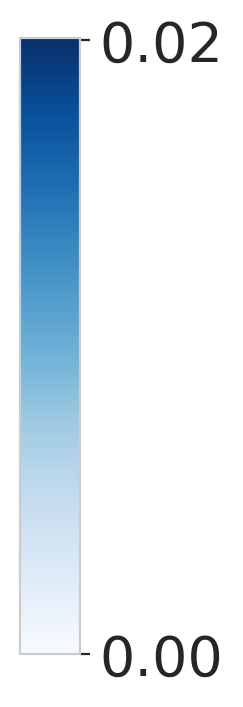

In [24]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Define the colormap and normalization
data = final_pos_patterns_df.avg_attr.values
vmin, vmax = data.min(), data.max()

p5 = np.percentile(data, 5)
p95 = np.percentile(data, 95)
vmin = 0
vmax = np.max(data)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='Blues', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(1, 4))
fig.subplots_adjust(left=0.5, right=0.8)
cbar = fig.colorbar(sm, cax=ax, ticks=[0, p95])
cbar.ax.set_yticklabels([f"{0:.2f}", f"{p95:.2f}"], fontsize=20)
# plt.savefig("plots/positive_colorbar.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()